In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_SEED = 42
LEARNING_RATE = 0.01
MAX_EPOCHS = 100

df = pd.read_csv("perceptron_data.csv")

required_columns = {"x1", "x2", "y"}
if not required_columns.issubset(df.columns):
    raise ValueError(f"Dataset must contain the columns: {sorted(required_columns)}")

X = df[["x1", "x2"]].to_numpy(dtype=float)
y = df["y"].to_numpy(dtype=float)

if not np.isfinite(X).all() or not np.isfinite(y).all():
    raise ValueError("The dataset contains missing or non-finite values.")
if not np.isin(y, [-1.0, 1.0]).all():
    raise ValueError("The target labels must be -1 or +1.")

print(f"Dataset shape: {X.shape}")
print(f"Class counts: {pd.Series(y).value_counts().sort_index().to_dict()}")
df.head()

Dataset shape: (100, 2)
Class counts: {-1.0: 50, 1.0: 50}


,x1,x2,y
0,6.822060,7.896793,1
1,7.886186,6.174578,1
2,6.227460,7.307143,1
3,2.097078,2.968645,-1
4,1.470240,2.513267,-1


In [22]:
def plot_decision_boundary(X, y, weights, title="Decision Boundary"):
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float)
    weights = np.asarray(weights, dtype=float).reshape(-1)

    if X.ndim != 2 or X.shape[1] != 2:
        raise ValueError("X must be a two-dimensional matrix with two features.")
    if weights.size != 3:
        raise ValueError("weights must contain [w0, w1, w2].")

    plt.figure(figsize=(8, 6))
    plt.scatter(X[y == 1, 0], X[y == 1, 1], color="tab:blue", label="Class +1", edgecolors="black")
    plt.scatter(X[y == -1, 0], X[y == -1, 1], color="tab:orange", label="Class -1", marker="x", s=70)

    x1_min, x1_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    x2_min, x2_max = X[:, 1].min() - 1, X[:, 1].max() + 1

    w0, w1, w2 = weights
    tolerance = 1e-12
    if abs(w2) > tolerance:
        x1_values = np.array([x1_min, x1_max])
        x2_values = -(w0 + w1 * x1_values) / w2
        plt.plot(x1_values, x2_values, "k--", linewidth=2, label=f"{w0:.2f} + {w1:.2f}x1 + {w2:.2f}x2 = 0")
    elif abs(w1) > tolerance:
        x1_boundary = -w0 / w1
        plt.axvline(x1_boundary, color="black", linestyle="--", linewidth=2, label=f"x1 = {x1_boundary:.2f}")
    else:
        plt.text(0.5, 0.5, "No unique decision boundary", transform=plt.gca().transAxes, ha="center")

    plt.xlim(x1_min, x1_max)
    plt.ylim(x2_min, x2_max)
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.title(title)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.show()

In [23]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# Define four distinct manual boundaries
manual_weight_sets = {
    "Boundary A": np.array([0.5, -1.2, 0.8]),
    "Boundary B": np.array([-2.0, 0.5, 1.0]),
    "Boundary C": np.array([-1.0, 0.8, -0.5]),
    "Boundary D": np.array([1.5, -0.3, -1.2])
}

boundary_names = list(manual_weight_sets.keys())
boundary_weights = list(manual_weight_sets.values())

# Set up static elements for the animation plot
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(X[y == 1, 0], X[y == 1, 1], color="tab:blue", label="Class +1", edgecolors="black")
ax.scatter(X[y == -1, 0], X[y == -1, 1], color="tab:orange", label="Class -1", marker="x", s=70)

x1_min, x1_max = X[:, 0].min() - 1, X[:, 0].max() + 1
x2_min, x2_max = X[:, 1].min() - 1, X[:, 1].max() + 1
ax.set_xlim(x1_min, x1_max)
ax.set_ylim(x2_min, x2_max)
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.grid(alpha=0.3)

line, = ax.plot([], [], "k--", linewidth=2, label="Manual Boundary")
title_text = ax.set_title("Manual Decision Boundaries Animation")
ax.legend()

def animate_manual(frame):
    name = boundary_names[frame]
    weights = boundary_weights[frame]
    w0, w1, w2 = weights

    tolerance = 1e-12
    if abs(w2) > tolerance:
        x1_values = np.array([x1_min, x1_max])
        x2_values = -(w0 + w1 * x1_values) / w2
        line.set_data(x1_values, x2_values)
    elif abs(w1) > tolerance:
        x1_boundary = -w0 / w1
        line.set_data([x1_boundary, x1_boundary], [x2_min, x2_max])
    else:
        line.set_data([], [])

    title_text.set_text(f"{name} (Weights: w0={w0:.1f}, w1={w1:.1f}, w2={w2:.1f})")
    return line, title_text

anim_manual = FuncAnimation(fig, animate_manual, frames=len(boundary_names), interval=1500, blit=True)
plt.close(fig)
HTML(anim_manual.to_jshtml())

In [24]:
def add_bias_column(features):
    if features.ndim != 2 or not np.isfinite(features).all():
        raise ValueError("Expected a finite two-dimensional feature matrix.")
    return np.column_stack((np.ones(features.shape[0]), features))


def initialize_parameters(num_features, random_state=RANDOM_SEED):
    rng = np.random.default_rng(random_state)
    return rng.normal(loc=0.0, scale=0.5, size=num_features + 1)


def predict(x, weights):
    score = x @ weights
    predictions = np.where(score >= 0, 1.0, -1.0)
    return predictions

def update_weights(weights, x, label, learning_rate):
    return weights + learning_rate * label * x


def compute_loss(X, y, weights):
    predictions = predict(X, weights)
    return int(np.sum(predictions != y))




In [25]:
def train_perceptron(X, y, epochs=100, learning_rate=0.1, initial_w=None):
    X_bias = add_bias_column(X)
    if initial_w is not None:
        w = initial_w.copy()
    else:
        w = initialize_parameters(X.shape[1])

    errors_per_epoch = []
    weight_history = [w.copy()]

    for epoch in range(epochs):
        for i in range(X_bias.shape[0]):
            x_i = X_bias[i]
            y_i = y[i]

            if y_i * predict(x_i, w) <= 0:
                w = update_weights(w, x_i, y_i, learning_rate)

            print(f"Epoch {epoch + 1} - Weights after update: {w} - Misclassifications: {compute_loss(X_bias, y, w)}")
            weight_history.append(w.copy())

        epoch_errors = compute_loss(X_bias, y, w)
        errors_per_epoch.append(epoch_errors)
        print(f"Epoch {epoch + 1} - Weights after epoch: {w} - Misclassifications: {epoch_errors}")

        if epoch_errors == 0:
            break

    return w, errors_per_epoch, weight_history

## 3. Visualize perceptron learning

Epoch 1 - Weights after update: [ 0.16235854 -0.45177145  0.45419353] - Misclassifications: 49
Epoch 1 - Weights after update: [ 0.17235854 -0.37290959  0.51593931] - Misclassifications: 40
Epoch 1 - Weights after update: [ 0.17235854 -0.37290959  0.51593931] - Misclassifications: 40
Epoch 1 - Weights after update: [ 0.16235854 -0.39388037  0.48625286] - Misclassifications: 43
Epoch 1 - Weights after update: [ 0.15235854 -0.40858277  0.46112018] - Misclassifications: 45
Epoch 1 - Weights after update: [ 0.15235854 -0.40858277  0.46112018] - Misclassifications: 45
Epoch 1 - Weights after update: [ 0.14235854 -0.41379755  0.44831862] - Misclassifications: 44
Epoch 1 - Weights after update: [ 0.14235854 -0.41379755  0.44831862] - Misclassifications: 44
Epoch 1 - Weights after update: [ 0.14235854 -0.41379755  0.44831862] - Misclassifications: 44
Epoch 1 - Weights after update: [ 0.14235854 -0.41379755  0.44831862] - Misclassifications: 44
Epoch 1 - Weights after update: [ 0.14235854 -0.41

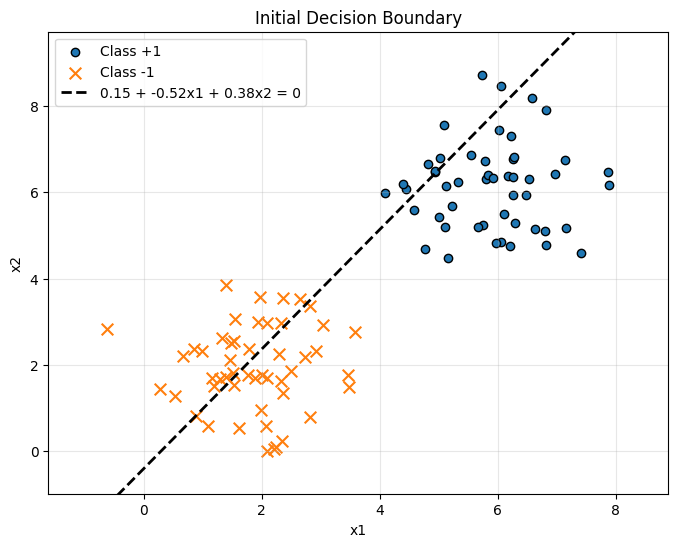

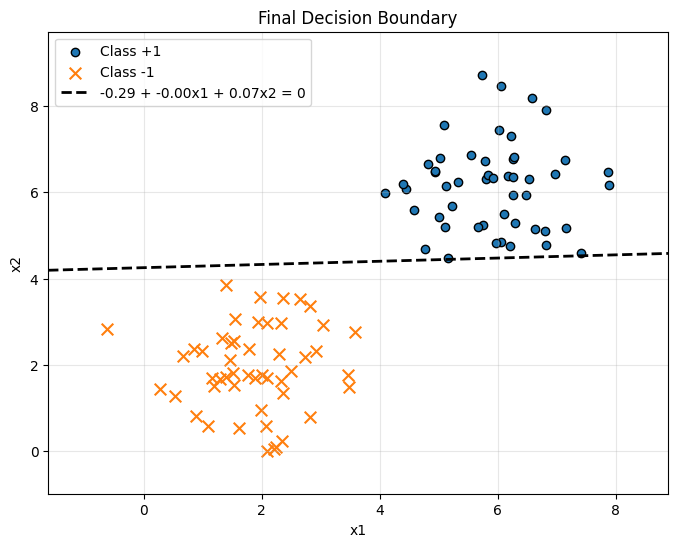

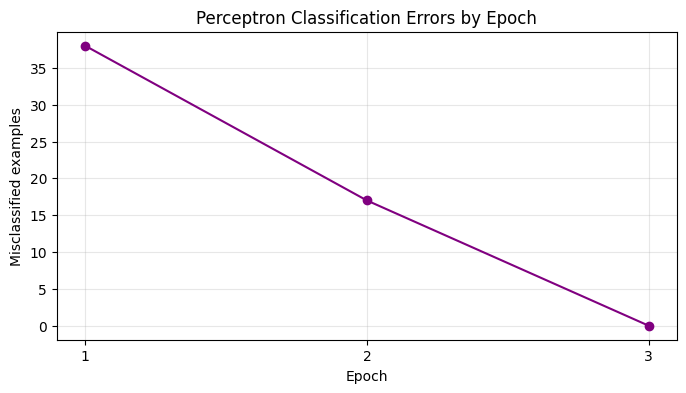

Initial weights: [ 0.1524 -0.52    0.3752]
Final weights: [-0.2876 -0.0025  0.0677]
Final training errors: 0
Every training example classified correctly: True


In [26]:
initial_weights = initialize_parameters(X.shape[1])
final_weights, errors_per_epoch, history_weights = train_perceptron(
    X,
    y,
    epochs=MAX_EPOCHS,
    learning_rate=LEARNING_RATE,
    initial_w=initial_weights
)

plot_decision_boundary(X, y, initial_weights, "Initial Decision Boundary")
plot_decision_boundary(X, y, final_weights, "Final Decision Boundary")

plt.figure(figsize=(8, 4))
epochs_range = list(range(1, len(errors_per_epoch) + 1))
plt.plot(epochs_range, errors_per_epoch, marker="o", color="purple")
plt.xlabel("Epoch")
plt.ylabel("Misclassified examples")
plt.title("Perceptron Classification Errors by Epoch")
plt.xticks(epochs_range)
plt.grid(alpha=0.3)
plt.show()

final_error = errors_per_epoch[-1]
print("Initial weights:", np.round(initial_weights, 4))
print("Final weights:", np.round(final_weights, 4))
print(f"Final training errors: {final_error}")
print(f"Every training example classified correctly: {final_error == 0}")

In [27]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# Set up figure
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(X[y == 1, 0], X[y == 1, 1], color="tab:blue", label="Class +1", edgecolors="black")
ax.scatter(X[y == -1, 0], X[y == -1, 1], color="tab:orange", label="Class -1", marker="x", s=70)

x1_min, x1_max = X[:, 0].min() - 1, X[:, 0].max() + 1
x2_min, x2_max = X[:, 1].min() - 1, X[:, 1].max() + 1
ax.set_xlim(x1_min, x1_max)
ax.set_ylim(x2_min, x2_max)
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.grid(alpha=0.3)

line, = ax.plot([], [], "k--", linewidth=2, label="Decision Boundary")
title_text = ax.set_title("Perceptron Learning Animation")
ax.legend()

def animate(frame):
    weights = history_weights[frame]
    w0, w1, w2 = weights
    tolerance = 1e-12
    if abs(w2) > tolerance:
        x1_values = np.array([x1_min, x1_max])
        x2_values = -(w0 + w1 * x1_values) / w2
        line.set_data(x1_values, x2_values)
    elif abs(w1) > tolerance:
        x1_boundary = -w0 / w1
        line.set_data([x1_boundary, x1_boundary], [x2_min, x2_max])
    else:
        line.set_data([], [])

    title_text.set_text(f"Perceptron Learning Animation - Epoch {frame} (Weights: {np.round(weights, 2)})")
    return line, title_text

anim = FuncAnimation(fig, animate, frames=len(history_weights), interval=800, blit=True)
plt.close(fig) # Prevent duplicate static plot display
HTML(anim.to_jshtml())

In [28]:
X_xor = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1],
], dtype=float)
y_xor = np.array([1, -1, -1, 1], dtype=float)

--- XOR Dataset Values ---
Point 1: x = [0. 0.], y = 1
Point 2: x = [0. 1.], y = -1
Point 3: x = [1. 0.], y = -1
Point 4: x = [1. 1.], y = 1
--------------------------


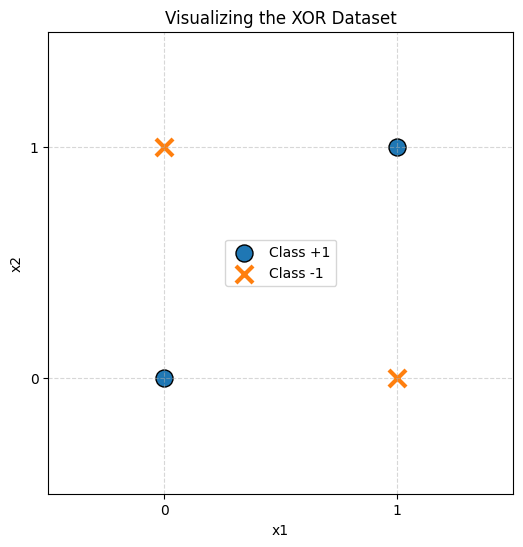

In [29]:
def plot_xor_dataset(X_xor, y_xor):

    print("--- XOR Dataset Values ---")
    for i in range(len(X_xor)):
        print(f"Point {i+1}: x = {X_xor[i]}, y = {int(y_xor[i])}")
    print("--------------------------")

    plt.figure(figsize=(6, 6))
    plt.scatter(X_xor[y_xor == 1, 0], X_xor[y_xor == 1, 1], color="tab:blue", marker="o", s=150, label="Class +1", edgecolors="black")
    plt.scatter(X_xor[y_xor == -1, 0], X_xor[y_xor == -1, 1], color="tab:orange", marker="x", s=150, linewidths=3, label="Class -1")


    plt.xlim(-0.5, 1.5)
    plt.ylim(-0.5, 1.5)
    plt.xticks([0, 1])
    plt.yticks([0, 1])
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.title("Visualizing the XOR Dataset")
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.legend(loc="center")
    plt.show()

plot_xor_dataset(X_xor, y_xor)

Epoch 1 - Weights after update: [0. 0. 0.] - Misclassifications: 2
Epoch 1 - Weights after update: [-0.01  0.   -0.01] - Misclassifications: 2
Epoch 1 - Weights after update: [-0.01  0.   -0.01] - Misclassifications: 2
Epoch 1 - Weights after update: [0.   0.01 0.  ] - Misclassifications: 2
Epoch 1 - Weights after epoch: [0.   0.01 0.  ] - Misclassifications: 2
Epoch 2 - Weights after update: [0.   0.01 0.  ] - Misclassifications: 2
Epoch 2 - Weights after update: [-0.01  0.01 -0.01] - Misclassifications: 3
Epoch 2 - Weights after update: [-0.02  0.   -0.01] - Misclassifications: 2
Epoch 2 - Weights after update: [-0.01  0.01  0.  ] - Misclassifications: 2
Epoch 2 - Weights after epoch: [-0.01  0.01  0.  ] - Misclassifications: 2
Epoch 3 - Weights after update: [0.   0.01 0.  ] - Misclassifications: 2
Epoch 3 - Weights after update: [-0.01  0.01 -0.01] - Misclassifications: 3
Epoch 3 - Weights after update: [-0.02  0.   -0.01] - Misclassifications: 2
Epoch 3 - Weights after update: [-0

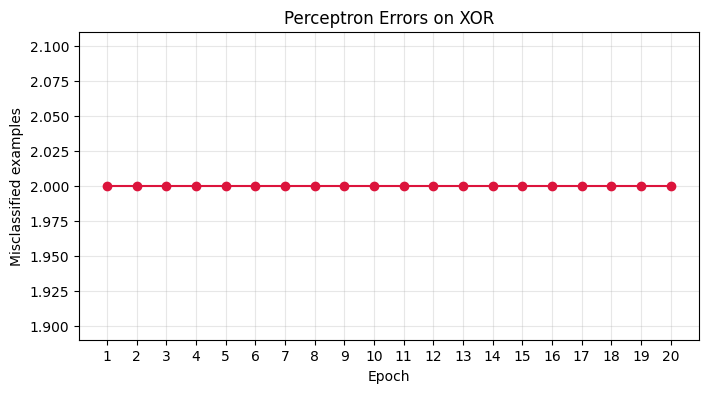

Final XOR weights: [-0.01  0.01  0.  ]
Final XOR predictions: [-1 -1  1  1]
Final XOR errors: 2
Conclusion: XOR is not linearly separable, so a single perceptron cannot solve it perfectly.


In [30]:
xor_weights, xor_errors_per_epoch, xor_history_weights = train_perceptron(
    X_xor,
    y_xor,
    epochs=20,
    learning_rate=LEARNING_RATE,
    initial_w=np.zeros(3)
)

xor_design = add_bias_column(X_xor)
xor_predictions = predict(xor_design, xor_weights)
xor_errors = compute_loss(xor_design, y_xor, xor_weights)

plt.figure(figsize=(8, 4))
epochs_range = list(range(1, len(xor_errors_per_epoch) + 1))
plt.plot(epochs_range, xor_errors_per_epoch, marker="o", color="crimson")
plt.xlabel("Epoch")
plt.ylabel("Misclassified examples")
plt.title("Perceptron Errors on XOR")
plt.xticks(epochs_range)
plt.grid(alpha=0.3)
plt.show()

print("Final XOR weights:", np.round(xor_weights, 4))
print("Final XOR predictions:", xor_predictions.astype(int))
print("Final XOR errors:", xor_errors)
print("Conclusion: XOR is not linearly separable, so a single perceptron cannot solve it perfectly.")